# U-GradCAM: Validation Explainability for U1 MobileNetV2

**Project:** Explainable Transfer Learning Framework for Fetal Ultrasound Standard Plane Classification  
**Selected frozen model:** `U1_MobileNetV2_frozen_seed42`  
**Purpose:** Produce reproducible Grad-CAM illustrations for selected **validation** images, without training or changing the selected model.

The source experiment used a frozen ImageNet MobileNetV2 backbone with a six-class softmax head. Input images were resized with padding to 224 × 224, remained in the pixel range [0, 255], and were rescaled to [-1, 1] **inside** the saved model. This notebook uses the same preprocessing.

**Run one section at a time and review its output. Do not use Run all.** The notebook does not load held-out test images, train a model, change class IDs, modify original manifests or overwrite the U1 checkpoint. It reads the formal U1 selection freeze record created before final test evaluation. Any saved Grad-CAM images should be treated as illustrations rather than medical or causal evidence.

Source data: [FETAL_PLANES_DB](https://zenodo.org/records/3904280). Avoid publicly publishing source images or associated patient identifiers without verifying permissions.

## Section 1 : Check the frozen U1 artifacts and Colab environment

Connect Google Drive if needed. Read the already-saved U1 checkpoint and model-selection freeze record; verify their checksums. A GPU is helpful, but not mandatory for a small set of images. Do not run any training cells from the original U1 notebook.

In [7]:
from pathlib import Path
import hashlib
import json
import platform

from google.colab import drive
import tensorflow as tf

ROOT = Path('/content/drive/MyDrive/ICTIU_Final_Projects')
if not ROOT.is_dir():
    drive.mount('/content/drive')
if not ROOT.is_dir():
    raise FileNotFoundError('Project Drive root is unavailable.')

PROJECT = ROOT / 'ultrasound'
U1_RUN = PROJECT / 'results/U1_MobileNetV2_frozen_seed42'
MODEL_PATH = U1_RUN / 'best_model.keras'
CONFIG_PATH = U1_RUN / 'configuration.json'
MANIFEST_PATH = PROJECT / 'splits/manifest_candidate.csv'
MAPPING_PATH = PROJECT / 'splits/class_mapping.json'
AUDIT_PATH = PROJECT / 'results/audit.json'
ZIP_PATH = PROJECT / 'archives/FETAL_PLANES_ZENODO.zip'
FREEZE_PATH = PROJECT / 'selection/U1_model_selection_freeze_2026-10-19.json'

needed = [MODEL_PATH, CONFIG_PATH, MANIFEST_PATH, MAPPING_PATH,
          AUDIT_PATH, ZIP_PATH, FREEZE_PATH]
missing = [str(p) for p in needed if not p.is_file()]
if missing:
    raise FileNotFoundError('Missing saved project files: ' + str(missing))

def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(4 * 1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

freeze = json.loads(FREEZE_PATH.read_text(encoding='utf-8'))
assert freeze['selected_experiment'] == 'U1_MobileNetV2_frozen_seed42'
assert freeze['decision_status'] == 'FROZEN_BEFORE_HELD_OUT_TEST'

for key, actual in [
    ('model_artifact', MODEL_PATH),
    ('configuration', CONFIG_PATH),
    ('manifest', MANIFEST_PATH),
    ('mapping_file', MAPPING_PATH),
]:
    saved = freeze[key]
    assert ROOT / saved['path_relative_to_root'] == actual, key
    if file_sha256(actual) != saved['sha256']:
        raise RuntimeError(f'Frozen artifact changed: {key}')

assert file_sha256(MODEL_PATH) == (
    '5154c6d97685c2ef39d3ba040a409443cc0f261e070ca627c24b940979b897ae'
)
assert file_sha256(MANIFEST_PATH) == (
    'ef6fec1a70e80a0b7ed34c990ebac2918ddc8a81dcef300aa244ce6ab1a5e1e0'
)

print('TensorFlow:', tf.__version__)
print('Python:', platform.python_version())
print('Visible GPUs:', tf.config.list_physical_devices('GPU'))
print('U1 checkpoint SHA-256:', file_sha256(MODEL_PATH))
print('Selection record:', FREEZE_PATH.name)
print('SECTION 1 PASS: Frozen U1 artifacts verified. No test images read.')


TensorFlow: 2.21.0
Python: 3.13.15
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
U1 checkpoint SHA-256: 5154c6d97685c2ef39d3ba040a409443cc0f261e070ca627c24b940979b897ae
Selection record: U1_model_selection_freeze_2026-10-19.json
SECTION 1 PASS: Frozen U1 artifacts verified. No test images read.


## Section 2 : Verify the fixed manifest and preselect validation cases

Select **two validation images per class** (12 images in total), using a fixed hash-based ranking and distinct patient groups. This selection is made before loading the model or seeing predictions, avoiding performance-based cherry-picking. The full manifest is read for split-integrity checks, but **no held-out test pixels** are accessed. Patient group IDs are only used in memory and will not be exported.

In [8]:
import pandas as pd

EXPECTED_CLASSES = {
    'Fetal abdomen': 0, 'Fetal brain': 1, 'Fetal femur': 2,
    'Fetal thorax': 3, 'Maternal cervix': 4, 'Other': 5,
}
class_to_id = json.loads(MAPPING_PATH.read_text(encoding='utf-8'))
audit = json.loads(AUDIT_PATH.read_text(encoding='utf-8'))
config = json.loads(CONFIG_PATH.read_text(encoding='utf-8'))
assert class_to_id == EXPECTED_CLASSES
assert freeze['class_to_id'] == EXPECTED_CLASSES
assert audit['manifest_sha256'] == file_sha256(MANIFEST_PATH)
assert audit['status'] == 'PASS_candidate_split_checks'
assert config['model'] == 'MobileNetV2'
assert config['backbone_frozen'] is True
assert config['manifest_sha256'] == file_sha256(MANIFEST_PATH)

df = pd.read_csv(MANIFEST_PATH)
assert len(df) == 12400
assert df['split'].value_counts().to_dict() == {
    'train': 5818, 'test': 5271, 'validation': 1311
}
assert (df['class_id'] == df['class_name'].map(class_to_id)).all()
assert not (df.groupby('group_id')['split'].nunique() > 1).any()
assert ((df['official_train'] == 0) == (df['split'] == 'test')).all()

val_df = df.loc[df['split'] == 'validation'].copy()
assert val_df['group_id'].nunique() == 180

# Fixed sampling policy established without looking at predictions.
# The model is not loaded until Section 4.
SAMPLES_PER_CLASS = 2
SELECTION_SEED = 'U1_gradcam_validation_seed42_v1'
val_df['_selection_hash'] = val_df['relative_path'].astype(str).map(
    lambda p: hashlib.sha256((SELECTION_SEED + '|' + p).encode('utf-8')).hexdigest()
)
val_df = val_df.sort_values(['class_id', '_selection_hash', 'relative_path'])
selected_rows = []
used_groups = set()
for cid in range(6):
    taken = 0
    for _, row in val_df.loc[val_df['class_id'] == cid].iterrows():
        group = str(row['group_id'])
        if group in used_groups:
            continue
        used_groups.add(group)
        selected_rows.append({
            'relative_path': str(row['relative_path']),
            'class_id': int(row['class_id']),
            'class_name': str(row['class_name']),
            'selection_hash': str(row['_selection_hash']),
        })
        taken += 1
        if taken == SAMPLES_PER_CLASS:
            break
    assert taken == SAMPLES_PER_CLASS, f'Not enough distinct patients for class {cid}'

cases = pd.DataFrame(selected_rows)
assert len(cases) == 12
assert cases['class_id'].value_counts().sort_index().to_dict() == {i: 2 for i in range(6)}
assert cases['relative_path'].is_unique
assert set(cases['relative_path']).issubset(set(val_df['relative_path'].astype(str)))
CLASS_NAMES = [name for name, cid in sorted(class_to_id.items(), key=lambda pair: pair[1])]

print('Selected validation examples:', len(cases))
print('Unique selected patient groups:', len(used_groups))
print(cases.groupby('class_name', sort=False).size().to_string())
print('SECTION 2 PASS: Case selection fixed before model predictions.')


Selected validation examples: 12
Unique selected patient groups: 12
class_name
Fetal abdomen      2
Fetal brain        2
Fetal femur        2
Fetal thorax       2
Maternal cervix    2
Other              2
SECTION 2 PASS: Case selection fixed before model predictions.


## Section 3 : Restore only the selected validation images

Use the existing archive already stored in Drive. Extract **only the 12 preselected validation images** into temporary Colab storage. Do not re-download the dataset or extract any held-out test image. If images already exist and their ZIP sizes match, reuse them.

In [9]:
import shutil
import stat
import zipfile
from pathlib import PurePosixPath

WORK = Path('/content/ictiu_data/ultrasound')
WORK.mkdir(parents=True, exist_ok=True)
image_paths = []

with zipfile.ZipFile(ZIP_PATH, 'r') as archive:
    for rel in cases['relative_path'].astype(str):
        safe = PurePosixPath(rel)
        if safe.is_absolute() or '..' in safe.parts or '\\' in rel:
            raise RuntimeError('Unsafe ZIP image path: ' + rel)
        if safe.suffix.lower() not in ('.png', '.jpg', '.jpeg'):
            raise RuntimeError('Unexpected image format: ' + rel)
        try:
            member = archive.getinfo(rel)
        except KeyError as error:
            raise FileNotFoundError('Image absent from saved ZIP: ' + rel) from error
        if member.is_dir() or member.file_size <= 0 or member.file_size > 30 * 1024**2:
            raise RuntimeError('Invalid ZIP image member: ' + rel)
        if stat.S_ISLNK(member.external_attr >> 16):
            raise RuntimeError('ZIP symlink is not allowed.')
        destination = WORK.joinpath(*safe.parts)
        if not destination.resolve().is_relative_to(WORK.resolve()):
            raise RuntimeError('Unsafe destination path.')
        destination.parent.mkdir(parents=True, exist_ok=True)
        if not destination.is_file() or destination.stat().st_size != member.file_size:
            partial = destination.with_name(destination.name + '.partial')
            with archive.open(member) as source, partial.open('wb') as output:
                shutil.copyfileobj(source, output)
            partial.replace(destination)
        assert destination.stat().st_size == member.file_size
        image_paths.append(destination)

assert len(image_paths) == 12
print('Restored or reused validation images:', len(image_paths))
print('Source ZIP:', ZIP_PATH.name)
print('SECTION 3 PASS: Validation images only; no test images extracted.')


Restored or reused validation images: 12
Source ZIP: FETAL_PLANES_ZENODO.zip
SECTION 3 PASS: Validation images only; no test images extracted.


## Section 4 : Load the original U1 model and check prediction provenance

Load the **saved checkpoint** in inference mode. Verify that the backbone, built-in MobileNetV2 Rescaling layer, pooling layer and trained head are present. Reconstruct exactly the U1 image decoding and `resize_with_pad` pipeline; compare predictions against the historical U1 validation predictions file.

In [10]:
import numpy as np
from tensorflow import keras

tf.keras.utils.set_random_seed(42)
IMG_SIZE = 224

saved_model = keras.models.load_model(str(MODEL_PATH), compile=False)
rescale_layers = [l for l in saved_model.layers if isinstance(l, keras.layers.Rescaling)]
backbone_layers = [l for l in saved_model.layers if isinstance(l, keras.Model)]
pool_layers = [l for l in saved_model.layers if isinstance(l, keras.layers.GlobalAveragePooling2D)]
dropout_layers = [l for l in saved_model.layers if isinstance(l, keras.layers.Dropout)]
assert all(len(group) == 1 for group in (
    rescale_layers, backbone_layers, pool_layers, dropout_layers
))
rescale = rescale_layers[0]
backbone = backbone_layers[0]
gap = pool_layers[0]
dropout = dropout_layers[0]
head = saved_model.get_layer('class_scores')
assert isinstance(head, keras.layers.Dense) and head.units == 6
assert backbone.trainable is False
assert abs(float(rescale.scale) - 1.0 / 127.5) < 1e-8
assert abs(float(rescale.offset) + 1.0) < 1e-8
assert backbone.layers[-1].name == 'out_relu', 'Unexpected backbone tail: inspect before continuing.'

def preprocess_u1_image(path):
    raw = tf.io.read_file(str(path))
    decoded = tf.io.decode_image(raw, channels=3, expand_animations=False)
    decoded.set_shape((None, None, 3))
    resized = tf.image.resize_with_pad(decoded, IMG_SIZE, IMG_SIZE)
    return tf.cast(resized, tf.float32)  # Rescaling occurs inside saved_model.

images = tf.stack([preprocess_u1_image(p) for p in image_paths], axis=0)
assert tuple(images.shape) == (12, 224, 224, 3)
assert float(tf.reduce_min(images)) >= 0.0
assert float(tf.reduce_max(images)) <= 255.0

saved_probs = saved_model(images, training=False).numpy()
assert saved_probs.shape == (12, 6)
assert np.allclose(saved_probs.sum(axis=1), 1.0, atol=1e-5)
predicted_ids = saved_probs.argmax(axis=1)

historical_path = U1_RUN / 'validation_predictions.csv'
if not historical_path.is_file():
    raise FileNotFoundError('Historical U1 validation predictions are required for verification.')
historical = pd.read_csv(historical_path).set_index('relative_path', verify_integrity=True)
for i, row in cases.iterrows():
    rel = row['relative_path']
    if rel not in historical.index:
        raise RuntimeError('Selected image missing from U1 validation predictions: ' + rel)
    old_pred = int(historical.loc[rel, 'predicted_id'])
    assert int(predicted_ids[i]) == old_pred, ('Historical U1 prediction differs', rel)

print('Frozen model:', saved_model.name)
print('Backbone:', backbone.name, '| Grad-CAM layer: out_relu')
print('Input range:', float(tf.reduce_min(images)), 'to', float(tf.reduce_max(images)))
print('Historical validation prediction agreement: 12/12')
print('SECTION 4 PASS: U1 inference and preprocessing reproduced.')


Frozen model: Ultrasound_MobileNetV2_frozen_baseline
Backbone: mobilenetv2_1.00_224 | Grad-CAM layer: out_relu
Input range: 0.0 to 255.0
Historical validation prediction agreement: 12/12
SECTION 4 PASS: U1 inference and preprocessing reproduced.


## Section 5 : Grad-CAM gradient and logit-inference smoke test

Construct the feature-map extractor at MobileNetV2's final convolution activation, `out_relu` (spatial 7 × 7). Grad-CAM uses the **predicted class logit**, reconstructed from the saved Dense weights, rather than a second learned head or probability averaging. Compare reconstructed probabilities with the unchanged full saved model. A missing/non-finite gradient stops this section.

In [11]:
# out_relu is the final backbone layer; its activation feeds U1's pooling layer.
cam_backbone = keras.Model(
    inputs=backbone.input,
    outputs=backbone.get_layer('out_relu').output,
    name='U1_MobileNetV2_out_relu_extractor'
)
assert tuple(cam_backbone.output.shape[1:3]) == (7, 7)

def gradcam_u1(image):
    image = tf.convert_to_tensor(image, dtype=tf.float32)[None, ...]
    with tf.GradientTape() as tape:
        spatial_features = cam_backbone(rescale(image, training=False), training=False)
        tape.watch(spatial_features)
        features = dropout(gap(spatial_features), training=False)
        logits = tf.linalg.matmul(features, head.kernel)
        if head.use_bias:
            logits = tf.nn.bias_add(logits, head.bias)
        probs = tf.nn.softmax(logits, axis=-1)
        chosen_class = int(tf.argmax(logits[0]).numpy())
        target_logit = logits[0, chosen_class]

    grads = tape.gradient(target_logit, spatial_features)
    if grads is None:
        raise RuntimeError('No gradient from class logit to the selected feature map.')
    if not bool(tf.reduce_all(tf.math.is_finite(grads))):
        raise RuntimeError('Non-finite Grad-CAM gradients.')

    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    raw_cam = tf.nn.relu(tf.reduce_sum(weights * spatial_features, axis=-1))
    peak = float(tf.reduce_max(raw_cam).numpy())
    heatmap = raw_cam / (tf.reduce_max(raw_cam) + 1e-8)
    heatmap = tf.image.resize(heatmap[..., None], (IMG_SIZE, IMG_SIZE),
                              method='bilinear')[0, :, :, 0]
    heatmap = tf.clip_by_value(heatmap, 0.0, 1.0).numpy()

    reconstructed = probs.numpy()
    original = saved_model(image, training=False).numpy()
    difference = float(np.max(np.abs(reconstructed - original)))
    if difference > 1e-5:
        raise RuntimeError(f'Reconstructed head differs from saved U1: {difference:.3g}')
    if not np.isfinite(heatmap).all():
        raise RuntimeError('Non-finite Grad-CAM heatmap.')

    return {
        'heatmap': heatmap,
        'predicted_id': chosen_class,
        'softmax_score': float(reconstructed[0, chosen_class]),
        'probability_max_difference': difference,
        'raw_cam_peak': peak,
        'gradient_l1': float(tf.reduce_sum(tf.abs(grads)).numpy()),
    }

smoke = gradcam_u1(images[0])
assert smoke['predicted_id'] == int(predicted_ids[0])
print('Target layer: out_relu (7 x 7 feature map)')
print('Predicted class:', CLASS_NAMES[smoke['predicted_id']])
print('U1 vs reconstructed inference max difference:',
      f"{smoke['probability_max_difference']:.8g}")
print('Gradient absolute sum:', f"{smoke['gradient_l1']:.6g}")
print('Raw Grad-CAM peak:', f"{smoke['raw_cam_peak']:.6g}")
if smoke['raw_cam_peak'] <= 0:
    print('WARNING: This class/sample produced an all-zero ReLU CAM; report it honestly.')
print('SECTION 5 PASS: Differentiable U1 Grad-CAM path verified.')


Target layer: out_relu (7 x 7 feature map)
Predicted class: Fetal abdomen
U1 vs reconstructed inference max difference: 0
Gradient absolute sum: 50.0415
Raw Grad-CAM peak: 0.264222
SECTION 5 PASS: Differentiable U1 Grad-CAM path verified.


## Section 6 : Visually inspect the first validation explanation

Display the original padded image, class activation heatmap and transparent overlay. This preview is not used to change the already-frozen model or replace selected samples. A warm region is a coarse model-attribution signal, **not** a verified anatomical structure, localization ground truth or medical diagnosis.

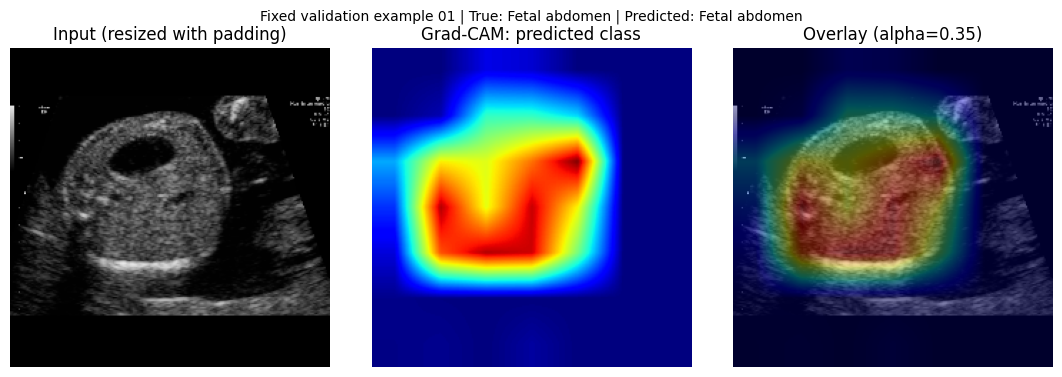

SECTION 6 PASS: First validation explanation previewed; nothing exported yet.


In [12]:
import matplotlib.pyplot as plt

def make_panel(image, result, true_label, sample_label):
    original = np.clip(np.asarray(image), 0, 255).astype(np.uint8)
    heat = result['heatmap']
    predicted_label = CLASS_NAMES[result['predicted_id']]
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
    axes[0].imshow(original)
    axes[0].set_title('Input (resized with padding)')
    axes[1].imshow(heat, cmap='jet', vmin=0, vmax=1)
    axes[1].set_title('Grad-CAM: predicted class')
    axes[2].imshow(original)
    axes[2].imshow(heat, cmap='jet', alpha=0.35, vmin=0, vmax=1)
    axes[2].set_title('Overlay (alpha=0.35)')
    for axis in axes:
        axis.axis('off')
    fig.suptitle(
        f'{sample_label} | True: {true_label} | Predicted: {predicted_label}',
        fontsize=10,
    )
    fig.tight_layout()
    return fig

preview = make_panel(images[0].numpy(), smoke, cases.iloc[0]['class_name'],
                     'Fixed validation example 01')
plt.show()
plt.close(preview)
print('SECTION 6 PASS: First validation explanation previewed; nothing exported yet.')


## Section 7 : Export validation Grad-CAM evidence to a new directory

Render and save all 12 preselected validation cases, an overview figure, an explanation table, and exact selection/provenance metadata. Use a new project-specific output folder; **never overwrite** the U1 baseline or an existing Grad-CAM run. Files are written to a temporary staging directory first and copied to Drive only after all cases have been generated. The selection is not changed based on correctness or heatmap quality.

In [13]:
from datetime import datetime, timezone

RUN_NAME = 'U_GradCAM_U1_validation_seed42'
OUT_DIR = PROJECT / 'results' / RUN_NAME
STAGE = Path('/content') / (RUN_NAME + '_staging')
if OUT_DIR.exists():
    raise FileExistsError(f'Existing results will not be overwritten: {OUT_DIR}')
if STAGE.exists():
    raise FileExistsError(f'Staging directory already exists; inspect it first: {STAGE}')
STAGE.mkdir(parents=True)
(STAGE / 'panels').mkdir()

records = []
heatmap_results = []
for i, row in cases.iterrows():
    result = gradcam_u1(images[i])
    assert result['predicted_id'] == int(predicted_ids[i])
    path = STAGE / 'panels' / f'validation_{i + 1:02d}_gradcam.png'
    panel = make_panel(images[i].numpy(), result, row['class_name'],
                       f'Fixed validation example {i + 1:02d}')
    panel.savefig(path, dpi=160, bbox_inches='tight')
    plt.close(panel)
    records.append({
        'example_number': i + 1,
        'partition': 'validation',
        'relative_path': row['relative_path'],
        'selection_hash': row['selection_hash'],
        'true_id': int(row['class_id']),
        'true_class': row['class_name'],
        'predicted_id': int(result['predicted_id']),
        'predicted_class': CLASS_NAMES[result['predicted_id']],
        'correct': bool(result['predicted_id'] == row['class_id']),
        'softmax_score_uncalibrated': result['softmax_score'],
        'raw_cam_peak': result['raw_cam_peak'],
        'gradient_l1': result['gradient_l1'],
        'full_model_reconstruction_max_abs_diff': result['probability_max_difference'],
        'panel_path': str(path.relative_to(STAGE)),
    })
    heatmap_results.append(result)

report = pd.DataFrame(records)
assert len(report) == 12 and set(report['partition']) == {'validation'}
report.to_csv(STAGE / 'validation_gradcam_examples.csv', index=False)

# Compact class overview: the first preselected case of each class.
fig, axes = plt.subplots(2, 3, figsize=(12, 7.8))
for cid, ax in enumerate(axes.flat):
    j = int(report.index[report['true_id'] == cid][0])
    im = np.clip(images[j].numpy(), 0, 255).astype(np.uint8)
    ax.imshow(im)
    ax.imshow(heatmap_results[j]['heatmap'], cmap='jet', vmin=0, vmax=1, alpha=0.35)
    status = 'correct' if report.loc[j, 'correct'] else 'incorrect'
    ax.set_title(f'True: {CLASS_NAMES[cid]}\nPredicted: {report.loc[j, "predicted_class"]} ({status})',
                 fontsize=9)
    ax.axis('off')
fig.suptitle('U1 Grad-CAM | fixed validation examples | illustrative only', fontsize=12)
fig.tight_layout()
fig.savefig(STAGE / 'gradcam_class_overview_validation.png', dpi=180, bbox_inches='tight')
plt.close(fig)

selection_payload = [
    {'relative_path': r['relative_path'], 'class_id': int(r['class_id']),
     'selection_hash': r['selection_hash']}
    for _, r in cases.iterrows()
]
metadata = {
    'experiment': RUN_NAME,
    'project': 'Explainable Transfer Learning Framework for Fetal Ultrasound Standard Plane Classification',
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'evaluation_partition': 'validation',
    'held_out_test_pixels_accessed': False,
    'new_model_training_performed': False,
    'selected_model': 'U1_MobileNetV2_frozen_seed42',
    'model_sha256': file_sha256(MODEL_PATH),
    'manifest_sha256': file_sha256(MANIFEST_PATH),
    'class_mapping_sha256': file_sha256(MAPPING_PATH),
    'freeze_file': str(FREEZE_PATH.relative_to(ROOT)),
    'freeze_sha256': file_sha256(FREEZE_PATH),
    'image_preprocessing': 'tf.io.decode_image RGB; tf.image.resize_with_pad 224x224; float32 [0,255]; model internal Rescaling',
    'gradcam_layer': 'MobileNetV2/out_relu (7x7)',
    'attribution_target': 'predicted-class pre-softmax logit',
    'cam_computation': 'mean spatial gradients -> channel weighting -> ReLU -> bilinear resize -> [0,1] scaling',
    'head_inference_check': 'Reconstructed logits/softmax compared with frozen full-model inference per image, tolerance 1e-5',
    'historical_prediction_comparison': '12/12 labels matched U1 validation_predictions.csv',
    'selection_rule': 'two images per class, lowest SHA-256 of seed|relative_path, no duplicate selected patient group',
    'selection_seed': SELECTION_SEED,
    'selection_made_before_predictions': True,
    'selection': selection_payload,
    'clinical_interpretation': 'Illustrative attribution only; not diagnosis, segmentation, causal explanation, or external validation.',
    'report_publication_note': 'Do not publicly distribute underlying images or identifiable metadata without permission.',
}
(STAGE / 'gradcam_provenance.json').write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False) + '\n', encoding='utf-8'
)

checksums = {}
for p in sorted(STAGE.rglob('*')):
    if p.is_file():
        checksums[str(p.relative_to(STAGE))] = file_sha256(p)
(STAGE / 'artifact_checksums.json').write_text(
    json.dumps(checksums, indent=2) + '\n', encoding='utf-8'
)

shutil.copytree(STAGE, OUT_DIR)
for relative, sha in checksums.items():
    assert file_sha256(OUT_DIR / relative) == sha, f'Export mismatch: {relative}'

print('SAVED:', OUT_DIR)
print('Saved explanation panels:', len(report))
print('Correct among fixed examples (descriptive only):', int(report['correct'].sum()), '/ 12')
print('Maximum U1 reconstruction difference:',
      float(report['full_model_reconstruction_max_abs_diff'].max()))
print('All-zero Grad-CAM cases:', int((report['raw_cam_peak'] <= 0).sum()))
print('SECTION 7 PASS: Validation-only Grad-CAM evidence exported without overwrites.')


SAVED: /content/drive/MyDrive/ICTIU_Final_Projects/ultrasound/results/U_GradCAM_U1_validation_seed42
Saved explanation panels: 12
Correct among fixed examples (descriptive only): 10 / 12
Maximum U1 reconstruction difference: 0.0
All-zero Grad-CAM cases: 0
SECTION 7 PASS: Validation-only Grad-CAM evidence exported without overwrites.


## Section 8 : Read-only export verification and report note

Verify the stored results without changing the model or results. When writing the report, document the fixed validation-example selection, `out_relu` target layer, logit gradients, zero-activation cases if any, and the limitations of heatmaps. Grad-CAM is not a diagnostic performance metric. The frozen U1 model remains the selected candidate for a **separate, planned one-time held-out test evaluation** only after the complete final-test protocol is verified.

In [14]:
saved_table = pd.read_csv(OUT_DIR / 'validation_gradcam_examples.csv')
saved_provenance = json.loads((OUT_DIR / 'gradcam_provenance.json').read_text())
saved_checksums = json.loads((OUT_DIR / 'artifact_checksums.json').read_text())
assert len(saved_table) == 12
assert saved_provenance['evaluation_partition'] == 'validation'
assert saved_provenance['selected_model'] == 'U1_MobileNetV2_frozen_seed42'
assert saved_provenance['held_out_test_pixels_accessed'] is False
assert saved_provenance['new_model_training_performed'] is False
for name, digest in saved_checksums.items():
    assert file_sha256(OUT_DIR / name) == digest
assert file_sha256(MODEL_PATH) == freeze['model_artifact']['sha256']

print('Verification passed for', len(saved_checksums), 'saved artifacts.')
print('Model checkpoint unchanged:', True)
print('Grad-CAM target: MobileNetV2/out_relu')
print('Image selection: validation only, 2 per class, fixed before model inference')
print('Held-out test evaluation: NOT performed')
print('SECTION 8 PASS: Ultrasound Grad-CAM module complete for this saved run.')


Verification passed for 15 saved artifacts.
Model checkpoint unchanged: True
Grad-CAM target: MobileNetV2/out_relu
Image selection: validation only, 2 per class, fixed before model inference
Held-out test evaluation: NOT performed
SECTION 8 PASS: Ultrasound Grad-CAM module complete for this saved run.
